# 1. Business Understanding

## 1.1 Contexte
Le diabète est une maladie métabolique chronique en forte progression dans le monde. Au-delà des dérèglements de la glycémie, le risque le plus critique et létal pour un patient diabétique réside dans la survenue de complications cardiovasculaires majeures : les personnes diabétiques présentent un risque 2 à 4 fois plus élevé de subir une maladie coronarienne ou un infarctus du myocarde, qui représentent plus de 65 % de la mortalité chez ces patients.

Pour les acteurs de la santé publique, les hôpitaux et les réseaux de soins primaires, les examens cardiologiques approfondis (coronarographies, électrocardiogrammes d’effort, dosages répétés de troponine) sont trop invasifs et coûteux pour être généralisés à l'ensemble de la population. Il est donc impératif de disposer d’outils de dépistage précoce non invasifs pour identifier les individus à haut risque d’accident cardiaque avant l'urgence vitale.

Ce projet s’appuie sur l’enquête américaine BRFSS 2015 (Behavioral Risk Factor Surveillance System), menée par les CDC auprès de plus de 250 000 adultes. Elle recueille des informations déclarées sur la santé, les habitudes de vie et la situation sociale. L’analyse vise à prédire la survenue de maladies coronariennes ou d'infarctus (`HeartDiseaseorAttack`) à partir de ces caractéristiques.

## 1.2 Problématique
- Comment prédire précocement le risque d'infarctus du myocarde ou de maladie coronarienne (`HeartDiseaseorAttack`) chez un individu à partir de ses antécédents médicaux, de son statut diabétique et de ses habitudes de vie ?

## 1.3 Objectifs métier et objectifs de fouille

### Objectif 6 : Prévention du risque cardiovasculaire majeur (Infarctus / Maladie coronarienne)
**BO6.** Réduire la mortalité évitable et les hospitalisations d'urgence pour accidents coronariens en priorisant la prise en charge préventive et les bilans cardiologiques chez les patients les plus vulnérables.

**DSO6.1.** Prédire si un individu présente un antécédent ou un risque avéré de maladie coronarienne / infarctus (`HeartDiseaseorAttack` = 1 vs 0) à partir de son profil métabolique, de son hygiène de vie et de ses caractéristiques socio-démographiques.

**DSO6.2.** Quantifier l'impact relatif du statut diabétique (`Diabetes_012`) et de la triade métabolique (diabète, hypertension, cholestérol) sur la probabilité de survenue d'un accident cardiaque afin de fournir des leviers de prévention actionnables.

## 1.4 Critères de succès (côté métier)
- **Objectif 6 :** Le modèle doit surpasser la référence naïve majoritaire en F1 macro et surtout maximiser le **Rappel (Sensibilité)** sur la classe positive (`HeartDiseaseorAttack` = 1), car en médecine, un faux négatif (patient à risque non détecté) entraîne une perte de chance critique.

## 1.5 Évaluation de la situation
- **Parties prenantes :** Autorités de santé publique, cardiologues, médecins généralistes, réseaux de prévention cardio-métabolique.
- **Ressources :** Une base certifiée de 253 680 réponses anonymisées collectées par les CDC, couvrant 22 indicateurs de santé et d'habitudes de vie.
- **Contraintes :** Données déclaratives transversales issues d'une enquête nationale (sans suivi prospectif en temps réel).
- **Hypothèses :** L’échantillon est représentatif de la population adulte et les déclarations sont globalement fiables.
- **Risques :**
  - Fort déséquilibre de classe : les cas d'infarctus représentent moins de 10 % de la population ;
  - Les corrélations observées décrivent des associations statistiques fortes et non des preuves strictes de causalité biologique.

## 1.6 Démarche
Le projet suit rigoureusement la méthode CRISP-DM : Compréhension du métier (Business Understanding), Compréhension des données (Data Understanding), Préparation des données (Data Preparation), Modélisation (Modeling), Évaluation (Evaluation), puis Déploiement et recommandations (Deployment).


## Compréhension des données
Le fichier BRFSS 2015 contient 253 680 réponses et 22 variables. Pour cet objectif, la cible étudiée est `HeartDiseaseorAttack` (0 = pas de maladie coronarienne ni d'infarctus, 1 = antécédent d'infarctus ou maladie coronarienne avérée) ; les 21 autres variables décrivent les comorbidités métaboliques (dont `Diabetes_012`), les habitudes de vie et la situation socio-économique.


In [32]:
# ============================================================
# IMPORTS GÉNÉRAUX
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuration d'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

print('Bibliothèques importées avec succès ✅')


Bibliothèques importées avec succès ✅


In [33]:
# ============================================================
# CHARGEMENT DU JEU DE DONNÉES
# ============================================================
from pathlib import Path

dataset_name = 'diabetes_012_health_indicators_BRFSS2015.csv'
possible_paths = [
    Path(dataset_name),
    Path('..') / dataset_name,
    Path('archive') / dataset_name,
    Path.cwd() / dataset_name
]
dataset_path = next((p for p in possible_paths if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(f"Fichier '{dataset_name}' introuvable.")

df = pd.read_csv(dataset_path)

print(f'Dimensions du jeu de données : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')
print(f"Nombre d'individus enquêtés   : {len(df):,}")


Dimensions du jeu de données : 253,680 lignes × 22 colonnes
Nombre d'individus enquêtés   : 253,680


### Repères sur les variables

| Groupe | Variables principales |
|---|---|
| **Cible étudiée** | `HeartDiseaseorAttack` (0 = Sain, 1 = Infarctus / Coronaropathie) |
| **Profil métabolique & Diabète** | `Diabetes_012`, `BMI`, `HighBP`, `HighChol`, `CholCheck` |
| **Comorbidités vasculaires & motrices** | `Stroke`, `DiffWalk` |
| **Habitudes de vie** | `PhysActivity`, `Fruits`, `Veggies`, `Smoker`, `HvyAlcoholConsump` |
| **Santé ressentie** | `GenHlth`, `MentHlth`, `PhysHlth` (jours d'incapacité sur 30 jours) |
| **Situation et accès aux soins** | `Age`, `Sex`, `Education`, `Income`, `AnyHealthcare`, `NoDocbcCost` |


### Exploration ciblée
Les graphiques ci-dessous analysent la distribution de la cible `HeartDiseaseorAttack`, puis son association majeure avec le statut diabétique (`Diabetes_012`), l'âge et l'hypertension artérielle.


Dimensions : 253,680 lignes x 22 colonnes
Valeurs manquantes : 0 | doublons exacts : 23,899


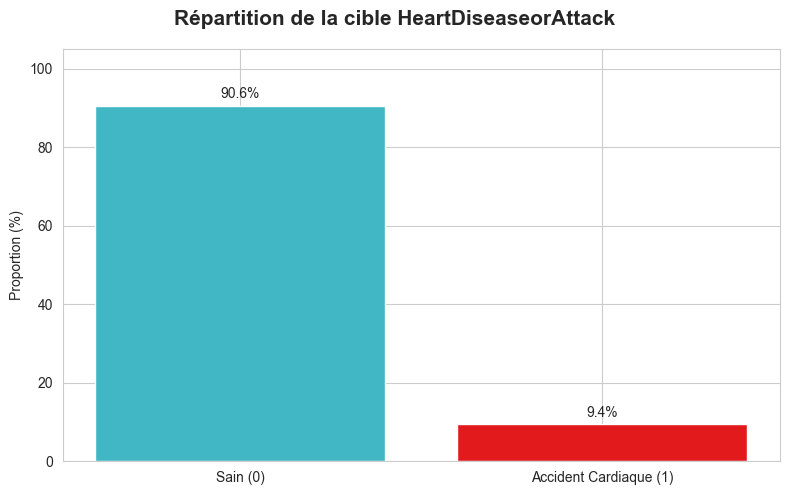

Cas sains (0)     : 229,787 (90.58 %)
Cas cardiaques (1): 23,893 (9.42 %)


In [34]:
# Répartition de la cible et aperçu de la qualité des données
print(f"Dimensions : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Valeurs manquantes : {int(df.isna().sum().sum()):,} | doublons exacts : {int(df.duplicated().sum()):,}")

heart_labels = ['Sain (0)', 'Accident Cardiaque (1)']
heart_counts = df['HeartDiseaseorAttack'].value_counts().sort_index()
heart_pct = df['HeartDiseaseorAttack'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(8, 5))
fig.suptitle('Répartition de la cible HeartDiseaseorAttack', fontsize=15, fontweight='bold')
bars = ax.bar(heart_labels, heart_pct.values, color=['#41b6c4', '#e31a1c'])
ax.set_ylabel('Proportion (%)')
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_ylim(0, 105)
fig.tight_layout()
plt.show()

print(f"Cas sains (0)     : {heart_counts[0]:,} ({heart_pct[0]:.2f} %)")
print(f"Cas cardiaques (1): {heart_counts[1]:,} ({heart_pct[1]:.2f} %)")


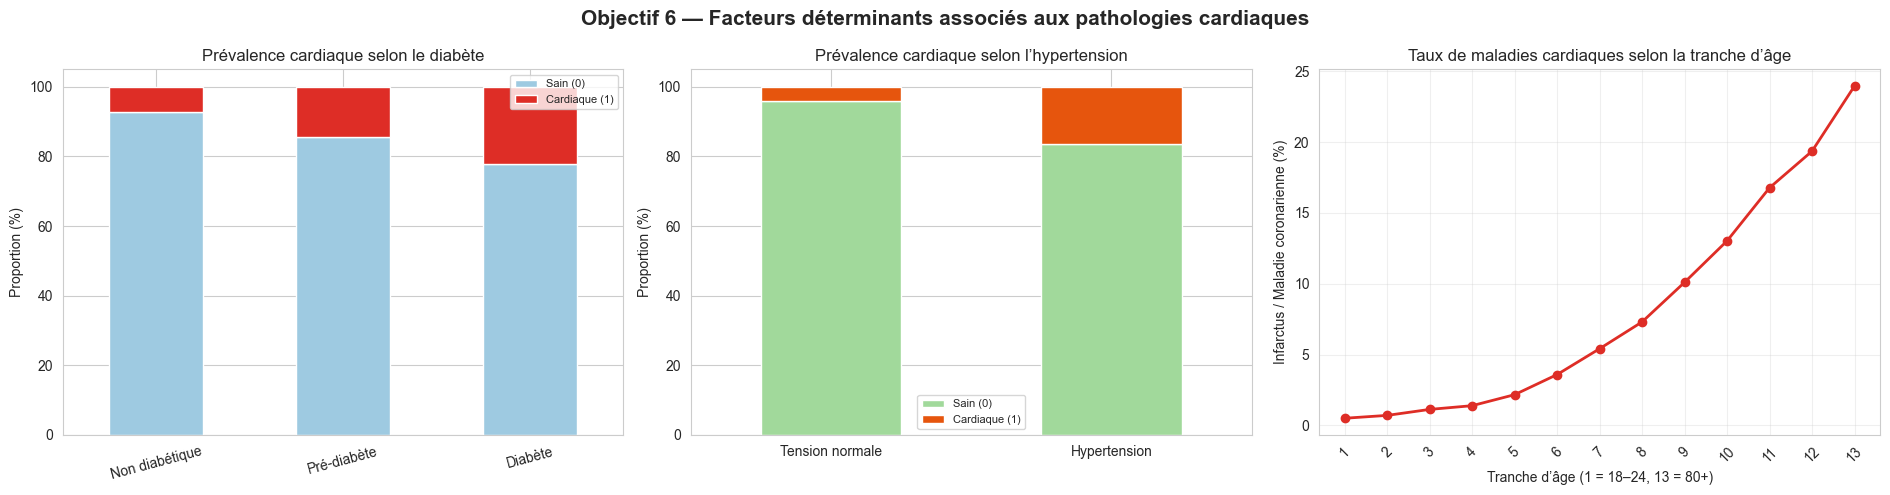

Risque cardiaque : Non diabétique = 7.2% | Diabétique = 22.3% (Facteur multiplicateur : 3.1x)


In [35]:
# Relations descriptives essentielles avec la pathologie cardiaque
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
fig.suptitle('Objectif 6 — Facteurs déterminants associés aux pathologies cardiaques', fontsize=15, fontweight='bold')

# 1. Prévalence selon le diabète
diab_heart = pd.crosstab(df['Diabetes_012'], df['HeartDiseaseorAttack'], normalize='index') * 100
diab_labels = ['Non diabétique', 'Pré-diabète', 'Diabète']
diab_heart.index = diab_labels
diab_heart.columns = ['Sain (0)', 'Cardiaque (1)']
diab_heart.plot(kind='bar', stacked=True, ax=axes[0], color=['#9ecae1', '#de2d26'])
axes[0].set_title('Prévalence cardiaque selon le diabète')
axes[0].set_ylabel('Proportion (%)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(fontsize=8)

# 2. Prévalence selon l'hypertension
bp_heart = pd.crosstab(df['HighBP'], df['HeartDiseaseorAttack'], normalize='index') * 100
bp_heart.index = ['Tension normale', 'Hypertension']
bp_heart.columns = ['Sain (0)', 'Cardiaque (1)']
bp_heart.plot(kind='bar', stacked=True, ax=axes[1], color=['#a1d99b', '#e6550d'])
axes[1].set_title('Prévalence cardiaque selon l’hypertension')
axes[1].set_ylabel('Proportion (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(fontsize=8)

# 3. Prévalence selon l'âge
age_heart = pd.crosstab(df['Age'], df['HeartDiseaseorAttack'], normalize='index')[1] * 100
axes[2].plot(age_heart.index, age_heart.values, marker='o', color='#de2d26', linewidth=2)
axes[2].set_title('Taux de maladies cardiaques selon la tranche d’âge')
axes[2].set_xlabel('Tranche d’âge (1 = 18–24, 13 = 80+)')
axes[2].set_ylabel('Infarctus / Maladie coronarienne (%)')
axes[2].set_xticks(age_heart.index)
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Risque cardiaque : Non diabétique = {diab_heart.loc['Non diabétique', 'Cardiaque (1)']:.1f}% | Diabétique = {diab_heart.loc['Diabète', 'Cardiaque (1)']:.1f}% (Facteur multiplicateur : {diab_heart.loc['Diabète', 'Cardiaque (1)'] / diab_heart.loc['Non diabétique', 'Cardiaque (1)']:.1f}x)")


### Anomalies et outils de détection
Les boxplots et la règle de l’IQR (écart interquartile) signalent des valeurs atypiques dans les mesures continues. Ce sont des alertes à examiner, pas des suppressions automatiques : les jours déclarés de mauvaise santé peuvent être élevés tout en restant valides.


In [36]:
# Détection des valeurs atypiques par la règle de l’IQR
anomaly_cols = ['BMI', 'MentHlth', 'PhysHlth']
def detect_outliers_iqr(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = data[(data[column] < lower) | (data[column] > upper)]
    return len(outliers), lower, upper

for col in anomaly_cols:
    n_outliers, lower, upper = detect_outliers_iqr(df, col)
    print(f'{col:12s} : {n_outliers:6d} valeurs atypiques (bornes IQR : [{lower:.2f}, {upper:.2f}])')


BMI          :   9847 valeurs atypiques (bornes IQR : [13.50, 41.50])
MentHlth     :  36208 valeurs atypiques (bornes IQR : [-3.00, 5.00])
PhysHlth     :  40949 valeurs atypiques (bornes IQR : [-4.50, 7.50])


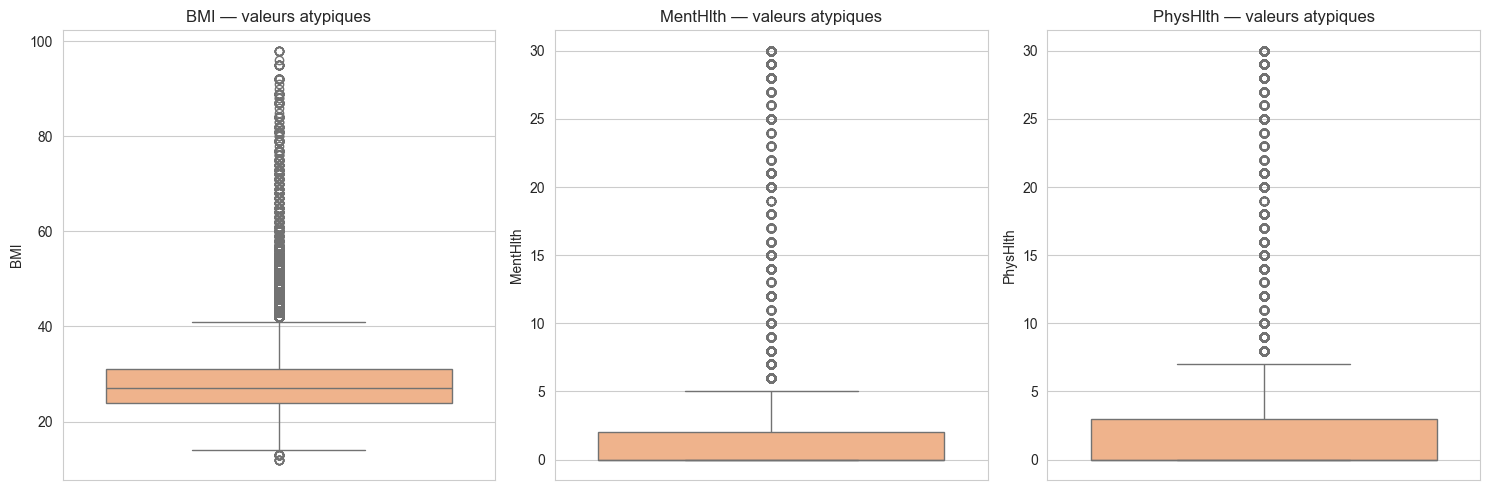

In [37]:
# Boxplots pour repérer les valeurs atypiques des mesures continues
fig, axes = plt.subplots(1, len(anomaly_cols), figsize=(15, 5))
for ax, col in zip(axes, anomaly_cols):
    sns.boxplot(y=df[col], ax=ax, color='#ffb07c')
    ax.set_title(f'{col} — valeurs atypiques')
plt.tight_layout()
plt.show()


## Synthèse du Compréhension des données

- **Qualité :** Aucune valeur manquante (`NaN = 0`) ; 23 899 doublons exacts, qui seront supprimés lors de la préparation.
- **Objectif 6 :** La cible `HeartDiseaseorAttack` est asymétrique (~9,4 % de cas positifs), ce qui justifie l'utilisation de modèles pondérés (`class_weight='balanced'`) et d'une métrique axée sur le Rappel.
- **Lien clinique fort :** Le statut diabétique (`Diabetes_012`), l'hypertension (`HighBP`) et l'âge (`Age`) constituent des prédicteurs très puissants du risque coronarien.
- Les distributions atypiques du BMI et des jours de mauvaise santé sont signalées par les boxplots ci-dessus ; elles seront traitées par plafonnement lors de la transformation.


# Objectif 6 — Prévention du risque cardiovasculaire et d'infarctus

**Base utilisée :** `diabetes_012_health_indicators_BRFSS2015.csv`

### Objectif métier (BO)
Réduire la mortalité évitable et les hospitalisations d'urgence pour accidents coronariens en priorisant la prise en charge préventive chez les patients les plus vulnérables.

### Objectifs de fouille (DSO)
DSO6.1. Prédire si un individu présente un antécédent ou un risque avéré d'infarctus / maladie coronarienne (`HeartDiseaseorAttack`), en s’appuyant sur ses indicateurs cliniques et son mode de vie.

## Préparation des données — Objectif 6
La préparation suit les étapes de nettoyage, transformation, ingénierie et sélection des variables, puis l’export du jeu préparé.

### Nettoyage des données
Suppression des doublons exacts, vérification des valeurs manquantes et validation de la cible binaire {0, 1} et des 21 variables explicatives.


In [38]:
# Data cleaning — chargement, validation et suppression des doublons
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

heart_source = pd.read_csv(dataset_path)
target_heart = 'HeartDiseaseorAttack'
if target_heart not in heart_source.columns:
    raise ValueError(f"La cible '{target_heart}' est absente.")

initial_rows = len(heart_source)
heart_source = heart_source.drop_duplicates().copy()
removed_heart_duplicates = initial_rows - len(heart_source)

if heart_source.isna().any().any():
    raise ValueError(f"Valeurs manquantes inattendues : {heart_source.isna().sum().to_dict()}")

y_heart = heart_source[target_heart].astype(int)
if not set(y_heart.unique()).issubset({0, 1}):
    raise ValueError(f"Valeurs HeartDiseaseorAttack inattendues : {sorted(y_heart.unique())}")

heart_class_names = {0: 'Sain (0)', 1: 'Accident Cardiaque (1)'}
X_heart_raw = heart_source.drop(columns=target_heart)

print(f'Lignes initiales : {initial_rows:,} | doublons supprimés : {removed_heart_duplicates:,} ({removed_heart_duplicates / initial_rows:.2%})')
print(f'Lignes conservées après nettoyage : {len(heart_source):,}')
print('Valeurs manquantes : aucune.')

duplicate_column_pairs = [(a, b) for i, a in enumerate(X_heart_raw.columns)
                           for b in X_heart_raw.columns[i + 1:] if X_heart_raw[a].equals(X_heart_raw[b])]
print('Colonnes strictement identiques :', duplicate_column_pairs or 'aucune')

heart_corr = X_heart_raw.corr(numeric_only=True)
correlated_pairs = [(a, b, float(heart_corr.loc[a, b]))
                    for i, a in enumerate(heart_corr.columns)
                    for b in heart_corr.columns[i + 1:]
                    if abs(heart_corr.loc[a, b]) > 0.8]
correlation_decisions = pd.DataFrame(correlated_pairs, columns=['Variable 1', 'Variable 2', 'Correlation'])
if correlation_decisions.empty:
    print('Paires avec |corrélation| > 0,8 : aucune ; prédicteurs conservés.')
else:
    display(correlation_decisions)


Lignes initiales : 253,680 | doublons supprimés : 23,899 (9.42%)
Lignes conservées après nettoyage : 229,781
Valeurs manquantes : aucune.
Colonnes strictement identiques : aucune
Paires avec |corrélation| > 0,8 : aucune ; prédicteurs conservés.


### Transformation des données
Séparation train/test stratifiée (80 % / 20 %), plafonnement du BMI à partir des quantiles 1 % et 99 % du train, puis standardisation des mesures continues avec un scaler ajusté sur le train uniquement afin d'éliminer tout risque de fuite de données (*Data Leakage*).


In [39]:
# Séparation stratifiée et transformation sans fuite de données
from sklearn.model_selection import train_test_split

X_heart_train_raw, X_heart_test_raw, y_heart_train, y_heart_test = train_test_split(
    X_heart_raw, y_heart, test_size=0.20, random_state=42, stratify=y_heart
)

bmi_lower, bmi_upper = X_heart_train_raw['BMI'].quantile([0.01, 0.99]).tolist()
bmi_capped_train_count = int(((X_heart_train_raw['BMI'] < bmi_lower) | (X_heart_train_raw['BMI'] > bmi_upper)).sum())
bmi_capped_total = int(((X_heart_raw['BMI'] < bmi_lower) | (X_heart_raw['BMI'] > bmi_upper)).sum())
continuous_heart = ['BMI', 'MentHlth', 'PhysHlth']

def transform_heart_features(frame):
    result = frame.copy()
    result['BMI_raw'] = result['BMI']
    result['BMI'] = result['BMI'].clip(lower=bmi_lower, upper=bmi_upper)
    scaled_values = heart_scaler.transform(result[continuous_heart])
    for i, column in enumerate(continuous_heart):
        result[f'{column}_scaled'] = scaled_values[:, i]
    return result

scaler_fit_data = X_heart_train_raw[continuous_heart].copy()
scaler_fit_data['BMI'] = scaler_fit_data['BMI'].clip(lower=bmi_lower, upper=bmi_upper)
heart_scaler = StandardScaler().fit(scaler_fit_data)

X_heart_train_transformed = transform_heart_features(X_heart_train_raw)
X_heart_test_transformed = transform_heart_features(X_heart_test_raw)

print(f'Train : {len(X_heart_train_raw):,} | test : {len(X_heart_test_raw):,}')
print('Stratification effectuée sur la cible binaire HeartDiseaseorAttack.')
print('Bornes BMI (quantiles train 1 %-99 %) :', (round(bmi_lower, 2), round(bmi_upper, 2)))
print(f'BMI à plafonner : {bmi_capped_train_count:,} valeurs train ; {bmi_capped_total:,} sur les données dédupliquées.')
print('StandardScaler ajusté sur les seules données train.')


Train : 183,824 | test : 45,957
Stratification effectuée sur la cible binaire HeartDiseaseorAttack.
Bornes BMI (quantiles train 1 %-99 %) : (18.0, 50.0)
BMI à plafonner : 2,797 valeurs train ; 3,484 sur les données dédupliquées.
StandardScaler ajusté sur les seules données train.


### Création de variables
Création des indicateurs dérivés cliniques : triade métabolique, fardeau vasculaire, score d’habitudes de vie, jours de santé cumulés et catégories d’IMC.


In [40]:
# Création des variables dérivées après transformation

def engineer_heart_features(frame):
    result = frame.copy()
    # 1. Triade métabolique (Diabète + Tension + Cholestérol)
    result['CardioMetabolicTriad'] = ((result['Diabetes_012'] >= 1).astype(int) + result['HighBP'] + result['HighChol'])
    # 2. Charge vasculaire cumulative
    result['VascularBurden'] = result['HighBP'] + result['HighChol'] + result['Stroke'] + (result['Diabetes_012'] == 2).astype(int)
    # 3. Score de mode de vie protecteur (0 à 5)
    result['LifestyleScore'] = (
        result['PhysActivity'] + result['Fruits'] + result['Veggies'] + 
        (1 - result['Smoker']) + (1 - result['HvyAlcoholConsump'])
    )
    # 4. Cumul des jours d'incapacité physique et mentale
    result['HealthDaysSum'] = result['MentHlth'] + result['PhysHlth']
    # 5. Catégorisation ordinale du BMI (normes OMS)
    result['BMI_cat'] = pd.cut(
        result['BMI'],
        bins=[0, 18.5, 25, 30, 35, 40, np.inf],
        labels=False,
        include_lowest=True
    ).astype('int8')
    return result

X_heart_train = engineer_heart_features(X_heart_train_transformed)
X_heart_test = engineer_heart_features(X_heart_test_transformed)

heart_candidate_features = [c for c in X_heart_train.columns if c not in set(continuous_heart + ['BMI_raw'])]
X_heart_train = X_heart_train[heart_candidate_features]
X_heart_test = X_heart_test[heart_candidate_features]

print(f'Variables candidates après ingénierie : {len(heart_candidate_features)}')


Variables candidates après ingénierie : 26


### Sélection des variables
Trois approches de classification (filtre ANOVA, wrapper RFE et importance intrinsèque Random Forest) sont ajustées sur le train uniquement. Une variable est retenue si elle figure dans le top 10 d’au moins deux méthodes sur trois.


In [41]:
# Sélection par vote adaptée à la cible binaire HeartDiseaseorAttack
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

heart_k = min(10, len(heart_candidate_features))

# 1. Filtre ANOVA
heart_filter = SelectKBest(f_classif, k=heart_k).fit(X_heart_train, y_heart_train)
filter_scores = pd.Series(np.nan_to_num(heart_filter.scores_, nan=0.0), index=heart_candidate_features)
filter_top = set(filter_scores.nlargest(heart_k).index)

# 2. Wrapper RFE sur échantillon stratifié
rfe_sample = X_heart_train.sample(n=min(50000, len(X_heart_train)), random_state=42)
rfe_target = y_heart_train.loc[rfe_sample.index]
heart_rfe = RFE(DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=42), n_features_to_select=heart_k, step=0.2).fit(rfe_sample, rfe_target)
rfe_ranks = pd.Series(heart_rfe.ranking_, index=heart_candidate_features)
rfe_top = set(rfe_ranks[rfe_ranks == 1].index)

# 3. Importance intrinsèque Random Forest pondérée
heart_intrinsic_model = RandomForestClassifier(n_estimators=80, max_depth=14, min_samples_leaf=10, class_weight='balanced', random_state=42, n_jobs=-1).fit(X_heart_train, y_heart_train)
intrinsic_scores = pd.Series(heart_intrinsic_model.feature_importances_, index=heart_candidate_features)
intrinsic_top = set(intrinsic_scores.nlargest(heart_k).index)

heart_selection_table = pd.DataFrame(index=heart_candidate_features)
heart_selection_table['Rang filtre f_classif'] = filter_scores.rank(ascending=False, method='min').astype(int)
heart_selection_table['Rang RFE'] = rfe_ranks.astype(int)
heart_selection_table['Rang importance RF'] = intrinsic_scores.rank(ascending=False, method='min').astype(int)
heart_selection_table['Votes top 10'] = [int(c in filter_top) + int(c in rfe_top) + int(c in intrinsic_top) for c in heart_candidate_features]
heart_selection_table['Décision'] = np.where(heart_selection_table['Votes top 10'] >= 2, 'Retenir', 'Retirer du modèle principal')

heart_selected_features = heart_selection_table.index[heart_selection_table['Votes top 10'] >= 2].tolist()
if not heart_selected_features:
    raise ValueError('Aucune variable retenue par consensus des méthodes de sélection.')

display(heart_selection_table.sort_values(['Votes top 10', 'Rang importance RF'], ascending=[False, True]))
print(f'Variables retenues : {len(heart_selected_features)} / {len(heart_candidate_features)}')


,Rang filtre f_classif,Rang RFE,Rang importance RF,Votes top 10,Décision
Age,4,1,1,3,Retenir
VascularBurden,1,1,2,3,Retenir
GenHlth,3,1,3,3,Retenir
DiffWalk,5,1,7,3,Retenir
PhysHlth_scaled,9,1,8,3,Retenir
CardioMetabolicTriad,2,4,4,2,Retenir
HighBP,6,5,5,2,Retenir
Sex,14,1,6,2,Retenir
HealthDaysSum,11,1,9,2,Retenir
Stroke,7,1,12,2,Retenir


Variables retenues : 10 / 26


### Export du jeu de données préparé
Export du jeu dédupliqué et enrichi dans `heart_disease_prepared.csv`. Les paramètres de plafonnement et de standardisation proviennent du train.


In [42]:
# Export du jeu préparé avec les transformations estimées sur le train
heart_prepared_features = engineer_heart_features(transform_heart_features(X_heart_raw))
heart_prepared = heart_prepared_features.copy()
heart_prepared[target_heart] = y_heart
heart_prepared_path = dataset_path.with_name('heart_disease_prepared.csv')
heart_prepared.to_csv(heart_prepared_path, index=False)
print(f'Jeu préparé sauvegardé : {heart_prepared_path.resolve()} ({len(heart_prepared):,} lignes).')


Jeu préparé sauvegardé : C:\Users\youss\OneDrive\Desktop\Project ML\archive\obj6\heart_disease_prepared.csv (229,781 lignes).


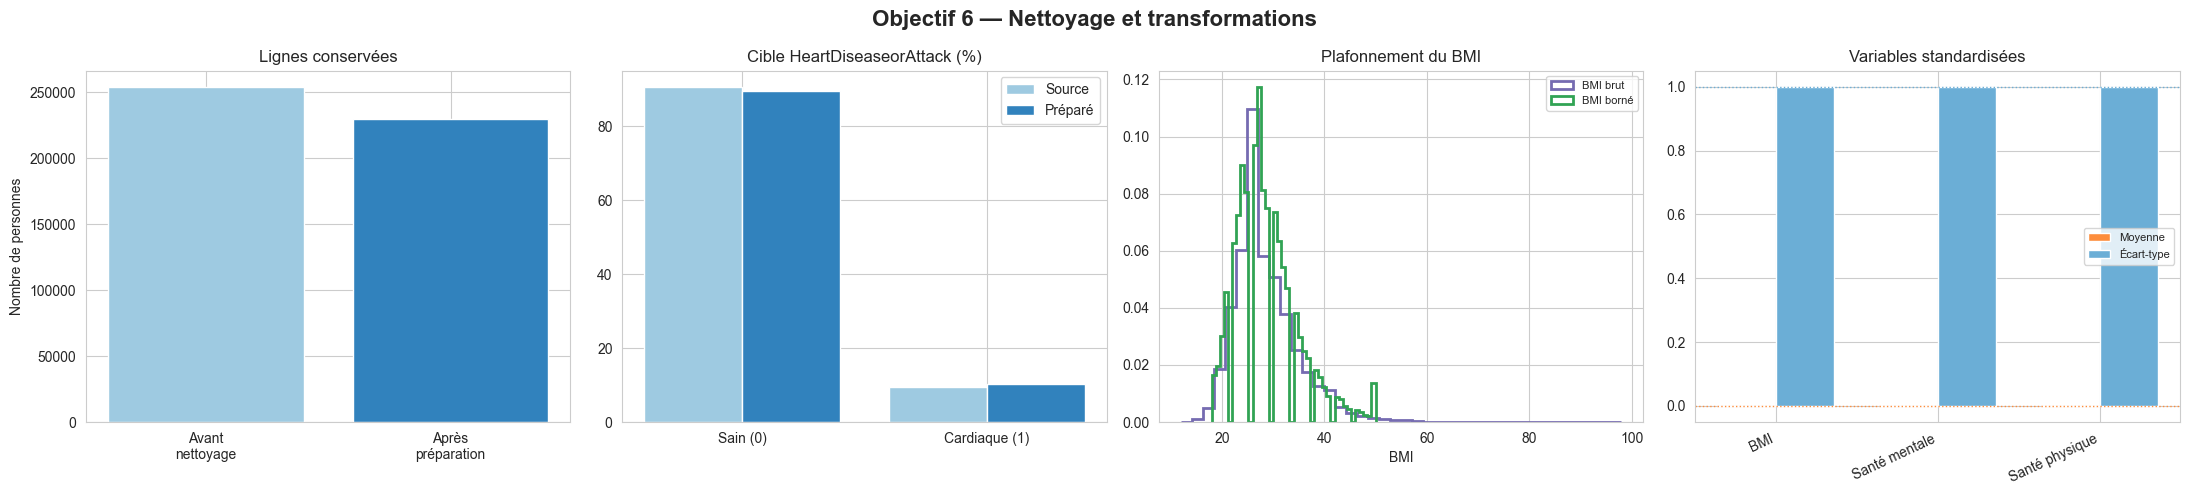

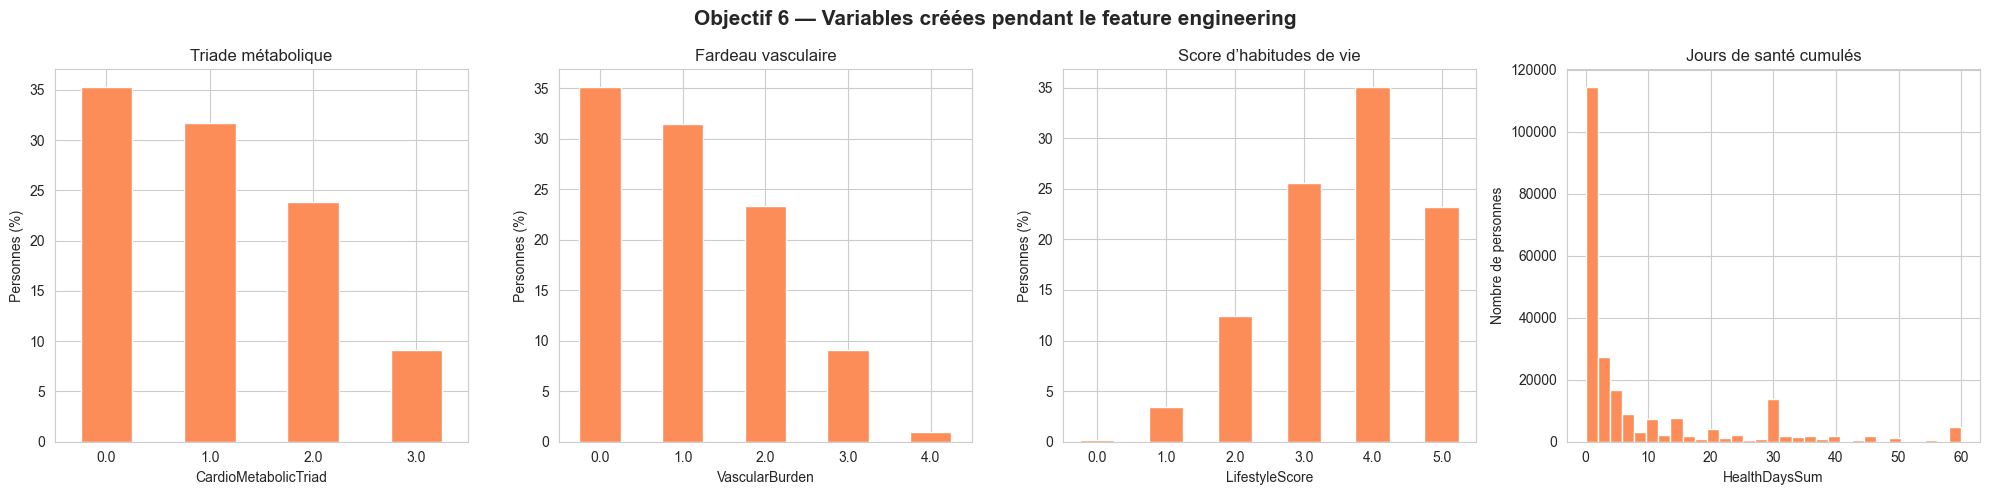

In [43]:
# Visualisations de validation de la préparation
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
fig.suptitle('Objectif 6 — Nettoyage et transformations', fontsize=16, fontweight='bold')

# 1. Lignes conservées
axes[0].bar(['Avant\nnettoyage', 'Après\npréparation'], [initial_rows, len(heart_prepared)], color=['#9ecae1', '#3182bd'])
axes[0].set_title('Lignes conservées')
axes[0].set_ylabel('Nombre de personnes')
axes[0].ticklabel_format(axis='y', style='plain')

# 2. Répartition de la cible
heart_source_pct = df['HeartDiseaseorAttack'].value_counts(normalize=True).sort_index() * 100
heart_prep_pct = heart_prepared['HeartDiseaseorAttack'].value_counts(normalize=True).sort_index() * 100
x = np.arange(2)
axes[1].bar(x - 0.2, heart_source_pct, width=0.4, label='Source', color='#9ecae1')
axes[1].bar(x + 0.2, heart_prep_pct, width=0.4, label='Préparé', color='#3182bd')
axes[1].set_xticks(x, ['Sain (0)', 'Cardiaque (1)'])
axes[1].set_title('Cible HeartDiseaseorAttack (%)')
axes[1].legend()

# 3. BMI avant vs après
axes[2].hist(heart_prepared['BMI_raw'], bins=40, density=True, histtype='step', linewidth=2, label='BMI brut', color='#756bb1')
axes[2].hist(heart_prepared['BMI'], bins=40, density=True, histtype='step', linewidth=2, label='BMI borné', color='#31a354')
axes[2].set_title('Plafonnement du BMI')
axes[2].set_xlabel('BMI')
axes[2].legend(fontsize=8)

# 4. Standardisation
scaled_columns = ['BMI_scaled', 'MentHlth_scaled', 'PhysHlth_scaled']
scaled_labels = ['BMI', 'Santé mentale', 'Santé physique']
scaled_means = heart_prepared[scaled_columns].mean()
scaled_stds = heart_prepared[scaled_columns].std()
x_sc = np.arange(len(scaled_columns))
axes[3].bar(x_sc - 0.18, scaled_means, width=0.36, label='Moyenne', color='#fd8d3c')
axes[3].bar(x_sc + 0.18, scaled_stds, width=0.36, label='Écart-type', color='#6baed6')
axes[3].axhline(0, color='#fd8d3c', linestyle=':', linewidth=1)
axes[3].axhline(1, color='#6baed6', linestyle=':', linewidth=1)
axes[3].set_xticks(x_sc, scaled_labels, rotation=25, ha='right')
axes[3].set_title('Variables standardisées')
axes[3].legend(fontsize=8)

fig.tight_layout()
plt.show()

# Variables dérivées
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Objectif 6 — Variables créées pendant le feature engineering', fontsize=15, fontweight='bold')
for ax, column, title in zip(
    axes,
    ['CardioMetabolicTriad', 'VascularBurden', 'LifestyleScore', 'HealthDaysSum'],
    ['Triade métabolique', 'Fardeau vasculaire', 'Score d’habitudes de vie', 'Jours de santé cumulés']
):
    if column == 'HealthDaysSum':
        ax.hist(heart_prepared[column], bins=31, color='#fc8d59', edgecolor='white')
        ax.set_ylabel('Nombre de personnes')
    else:
        heart_prepared[column].value_counts(normalize=True).sort_index().mul(100).plot.bar(ax=ax, color='#fc8d59')
        ax.set_ylabel('Personnes (%)')
        ax.tick_params(axis='x', rotation=0)
    ax.set_title(title)
    ax.set_xlabel(column)
fig.tight_layout()
plt.show()


# 1. Modélisation — Objectif 6
La cible `HeartDiseaseorAttack` est binaire : 0 = Pas d'antécédent cardiaque, 1 = Infarctus / Cardiopathie coronarienne. La sélection des variables et le réglage des modèles s’effectuent sur le train ; le test est réservé à l’évaluation finale.


## 1.1 Préparer les données d’entrée
On conserve uniquement les variables retenues par le vote multicritère. Le jeu de test ne participe ni à la sélection ni à la validation croisée.


In [44]:
if not heart_selected_features:
    raise ValueError('La liste des variables retenues par le vote est vide.')

X_train = X_heart_train.loc[:, heart_selected_features].copy()
X_test = X_heart_test.loc[:, heart_selected_features].copy()
y_train = y_heart_train.copy()
y_test = y_heart_test.copy()

if not X_train.index.equals(y_train.index) or not X_test.index.equals(y_test.index):
    raise ValueError('Les index des variables et des cibles ne sont pas alignés.')

print(f'X_entraînement : {X_train.shape} | y_entraînement : {y_train.shape}')
print(f'X_test réservé à l’évaluation finale : {X_test.shape} | y_test : {y_test.shape}')
print('Variables retenues :', heart_selected_features)


X_entraînement : (183824, 10) | y_entraînement : (183824,)
X_test réservé à l’évaluation finale : (45957, 10) | y_test : (45957,)
Variables retenues : ['HighBP', 'Stroke', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'PhysHlth_scaled', 'CardioMetabolicTriad', 'VascularBurden', 'HealthDaysSum']


## 1.2 Modèle de référence (baseline)
Le classifieur naïf prédit toujours la classe majoritaire du train (classe 0). Son score F1 macro servira de référence minimale à dépasser.


In [45]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate

heart_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
heart_scoring = make_scorer(f1_score, average='macro', zero_division=0)
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_cv = cross_validate(
    baseline_model, X_train, y_train, cv=heart_cv, scoring=heart_scoring,
    return_train_score=True, n_jobs=-1
)
print(f"Baseline — F1 macro entraînement : {baseline_cv['train_score'].mean():.3f}")
print(f"Baseline — F1 macro validation : {baseline_cv['test_score'].mean():.3f} ± {baseline_cv['test_score'].std():.3f}")


Baseline — F1 macro entraînement : 0.473
Baseline — F1 macro validation : 0.473 ± 0.000


## 1.3 Modèle 1 : Random Forest (Bagging / Bootstrap Aggregating)
Chaque arbre est entraîné sur un échantillon bootstrap et les arbres votent pour la classe finale. La recherche teste `n_estimators`, `max_features`, `min_samples_leaf` et `class_weight` ; `random_state=42` assure la reproductibilité.


In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_model = RandomForestClassifier(criterion='gini', random_state=42, n_jobs=-1)
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_features': ['sqrt', 0.8],
    'min_samples_leaf': [5, 20],
    'class_weight': [None, 'balanced'],
}
rf_search = RandomizedSearchCV(
    rf_model, rf_param_grid, n_iter=8, scoring=heart_scoring, cv=heart_cv,
    n_jobs=1, return_train_score=True, refit=True, random_state=42, verbose=1
)
rf_search.fit(X_train, y_train)
rf_best_index = rf_search.best_index_
print('Meilleurs paramètres Random Forest :', rf_search.best_params_)
print(f"F1 macro entraînement (moyenne des plis) : {rf_search.cv_results_['mean_train_score'][rf_best_index]:.3f}")
print(f"F1 macro validation : {rf_search.best_score_:.3f} ± {rf_search.cv_results_['std_test_score'][rf_best_index]:.3f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Meilleurs paramètres Random Forest : {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced'}
F1 macro entraînement (moyenne des plis) : 0.636
F1 macro validation : 0.602 ± 0.002


## 1.4 Modèle 2 : Gradient Boosting (Boosting)
Les arbres sont ajoutés séquentiellement pour corriger les résidus d'erreurs du modèle précédent. `n_iter_no_change` avec `validation_fraction` active l’arrêt anticipé pour limiter le surapprentissage.


In [16]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

boosting_model = GradientBoostingClassifier(
    random_state=42, n_iter_no_change=10, validation_fraction=0.1, tol=1e-4
)
boosting_param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3],
}
boosting_search = GridSearchCV(
    boosting_model, boosting_param_grid, scoring=heart_scoring, cv=heart_cv,
    n_jobs=1, return_train_score=True, refit=True, verbose=1
)
boosting_search.fit(X_train, y_train)
boosting_best_index = boosting_search.best_index_
print('Meilleurs paramètres Gradient Boosting :', boosting_search.best_params_)
print(f"F1 macro entraînement (moyenne des plis) : {boosting_search.cv_results_['mean_train_score'][boosting_best_index]:.3f}")
print(f"F1 macro validation : {boosting_search.best_score_:.3f} ± {boosting_search.cv_results_['std_test_score'][boosting_best_index]:.3f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Meilleurs paramètres Gradient Boosting : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
F1 macro entraînement (moyenne des plis) : 0.560
F1 macro validation : 0.559 ± 0.003


## 1.5 Réglage des hyperparamètres et comparaison entraînement / validation
Les meilleurs paramètres sont choisis par F1 macro moyen sur une validation croisée stratifiée à trois plis. L’écart entre le F1 macro entraînement et validation aide à repérer un éventuel surapprentissage.


In [17]:
from IPython.display import display

heart_model_comparison = pd.DataFrame([
    {
        'Modèle': 'Baseline majoritaire',
        'F1 macro entraînement': baseline_cv['train_score'].mean(),
        'F1 macro validation': baseline_cv['test_score'].mean(),
        'Écart entraînement-validation': baseline_cv['train_score'].mean() - baseline_cv['test_score'].mean(),
    },
    {
        'Modèle': 'Random Forest',
        'F1 macro entraînement': rf_search.cv_results_['mean_train_score'][rf_best_index],
        'F1 macro validation': rf_search.best_score_,
        'Écart entraînement-validation': rf_search.cv_results_['mean_train_score'][rf_best_index] - rf_search.best_score_,
    },
    {
        'Modèle': 'Gradient Boosting',
        'F1 macro entraînement': boosting_search.cv_results_['mean_train_score'][boosting_best_index],
        'F1 macro validation': boosting_search.best_score_,
        'Écart entraînement-validation': boosting_search.cv_results_['mean_train_score'][boosting_best_index] - boosting_search.best_score_,
    },
])
heart_model_comparison['Supérieur à la baseline'] = heart_model_comparison['F1 macro validation'] > baseline_cv['test_score'].mean()
display(heart_model_comparison.sort_values('F1 macro validation', ascending=False).reset_index(drop=True))


,Modèle,F1 macro entraînement,F1 macro validation,Écart entraînement-validation,Supérieur à la baseline
0,Random Forest,0.636484,0.602363,3.412099e-02,True
1,Gradient Boosting,0.560491,0.558501,1.989120e-03,True
2,Baseline majoritaire,0.472791,0.472791,-5.833445e-12,False


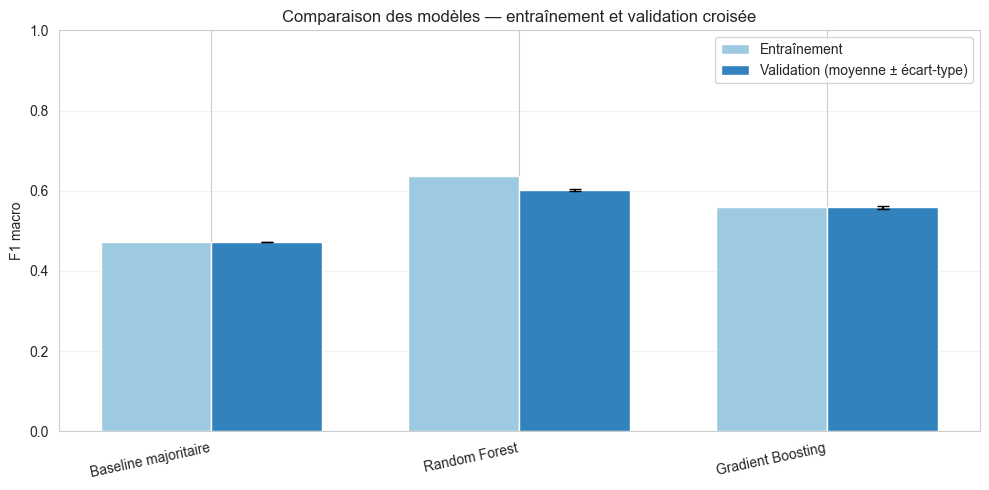

In [18]:
import matplotlib.pyplot as plt
import numpy as np

heart_plot_models = heart_model_comparison['Modèle'].tolist()
heart_plot_train = heart_model_comparison['F1 macro entraînement'].to_numpy()
heart_plot_validation = heart_model_comparison['F1 macro validation'].to_numpy()
heart_plot_validation_std = np.array([
    baseline_cv['test_score'].std(),
    rf_search.cv_results_['std_test_score'][rf_best_index],
    boosting_search.cv_results_['std_test_score'][boosting_best_index],
])
heart_plot_x = np.arange(len(heart_plot_models))
heart_plot_width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(heart_plot_x - heart_plot_width / 2, heart_plot_train, heart_plot_width, label='Entraînement', color='#9ecae1')
ax.bar(heart_plot_x + heart_plot_width / 2, heart_plot_validation, heart_plot_width,
       yerr=heart_plot_validation_std, capsize=4, label='Validation (moyenne ± écart-type)', color='#3182bd')
ax.set_xticks(heart_plot_x, heart_plot_models, rotation=12, ha='right')
ax.set_ylabel('F1 macro')
ax.set_ylim(0, 1)
ax.set_title('Comparaison des modèles — entraînement et validation croisée')
ax.legend()
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()


### Visualisation des hyperparamètres testés
Les graphiques montrent les configurations testées pour chaque modèle, classées selon leur F1 macro en validation croisée.


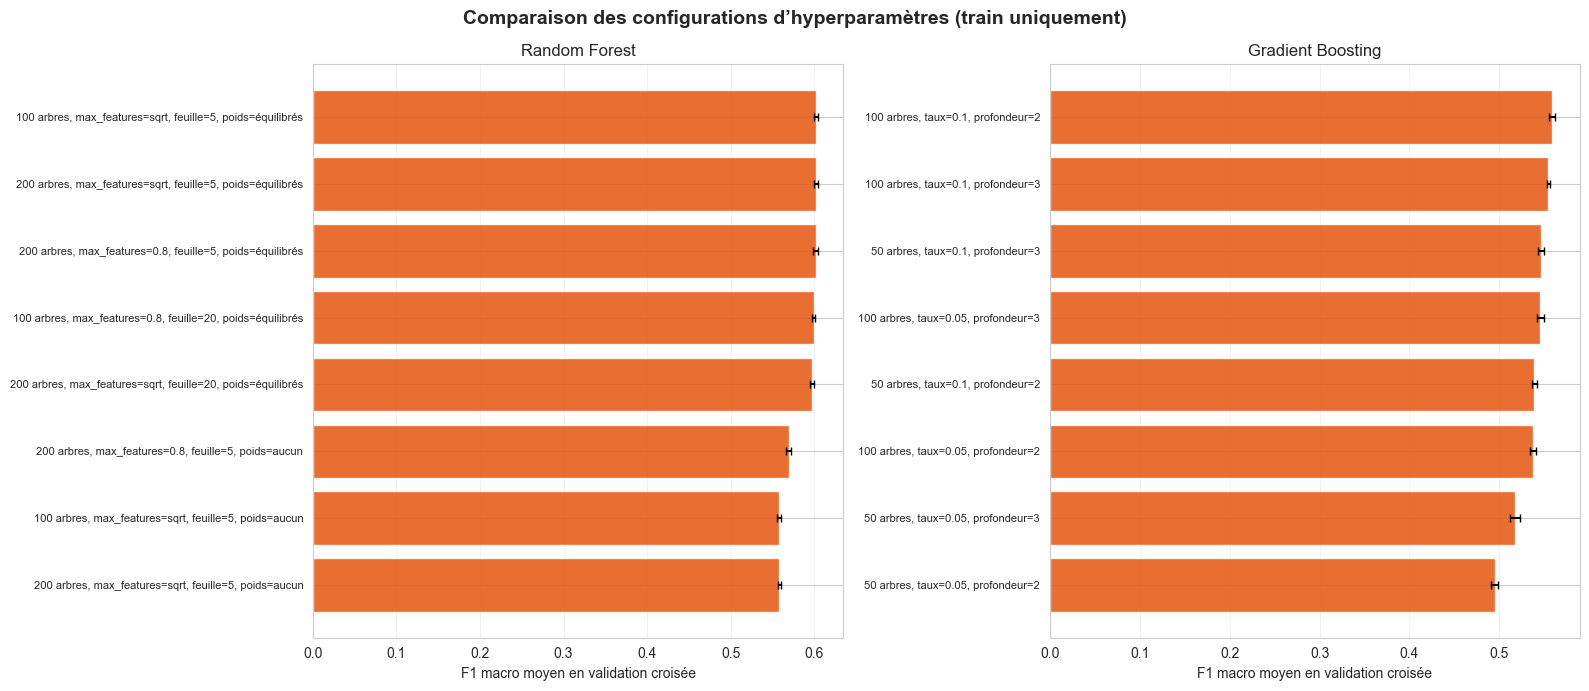

In [19]:
rf_results_plot = pd.DataFrame(rf_search.cv_results_).sort_values('mean_test_score').tail(8)
rf_config_labels = [
    f"{row['param_n_estimators']} arbres, max_features={row['param_max_features']}, feuille={row['param_min_samples_leaf']}, poids={'équilibrés' if row['param_class_weight'] == 'balanced' else 'aucun'}"
    for _, row in rf_results_plot.iterrows()
]
boosting_results_plot = pd.DataFrame(boosting_search.cv_results_).sort_values('mean_test_score').tail(8)
boosting_config_labels = [
    f"{row['param_n_estimators']} arbres, taux={row['param_learning_rate']}, profondeur={row['param_max_depth']}"
    for _, row in boosting_results_plot.iterrows()
]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, results, labels, title in [
    (axes[0], rf_results_plot, rf_config_labels, 'Random Forest'),
    (axes[1], boosting_results_plot, boosting_config_labels, 'Gradient Boosting'),
]:
    positions = range(len(results))
    ax.barh(positions, results['mean_test_score'], xerr=results['std_test_score'], capsize=3, color='#e6550d', alpha=0.85)
    ax.set_yticks(list(positions), labels, fontsize=8)
    ax.set_xlabel('F1 macro moyen en validation croisée')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.25)
fig.suptitle('Comparaison des configurations d’hyperparamètres (train uniquement)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()


## 1.6 Déséquilibre des classes
La proportion de cas positifs est d'environ 9,4 % dans le train. Le réglage Random Forest compare l’effet déterminant de `class_weight='balanced'` pour forcer l'algorithme à prêter une attention accrue aux cas cardiaques.


In [20]:
heart_train_class_counts = y_train.value_counts().sort_index().rename(index=heart_class_names)
heart_train_class_distribution = pd.DataFrame({
    'Effectif train': heart_train_class_counts,
    'Part train (%)': (y_train.value_counts(normalize=True).sort_index().rename(index=heart_class_names) * 100).round(2),
})
display(heart_train_class_distribution)

rf_weight_results = pd.DataFrame(rf_search.cv_results_)
rf_weight_results['Pondération'] = rf_weight_results['param_class_weight'].apply(lambda weight: 'aucun' if pd.isna(weight) else weight)
rf_weight_scores = rf_weight_results.groupby('Pondération')['mean_test_score'].mean()
print('F1 macro moyen en validation, par pondération des classes :')
print(rf_weight_scores.round(3))
print('class_weight retenu pour le meilleur Random Forest :', rf_search.best_params_['class_weight'])


,Effectif train,Part train (%)
HeartDiseaseorAttack,,
Sain (0),164850,89.68
Accident Cardiaque (1),18974,10.32


F1 macro moyen en validation, par pondération des classes :
Pondération
aucun       0.562
balanced    0.601
Name: mean_test_score, dtype: float64
class_weight retenu pour le meilleur Random Forest : balanced


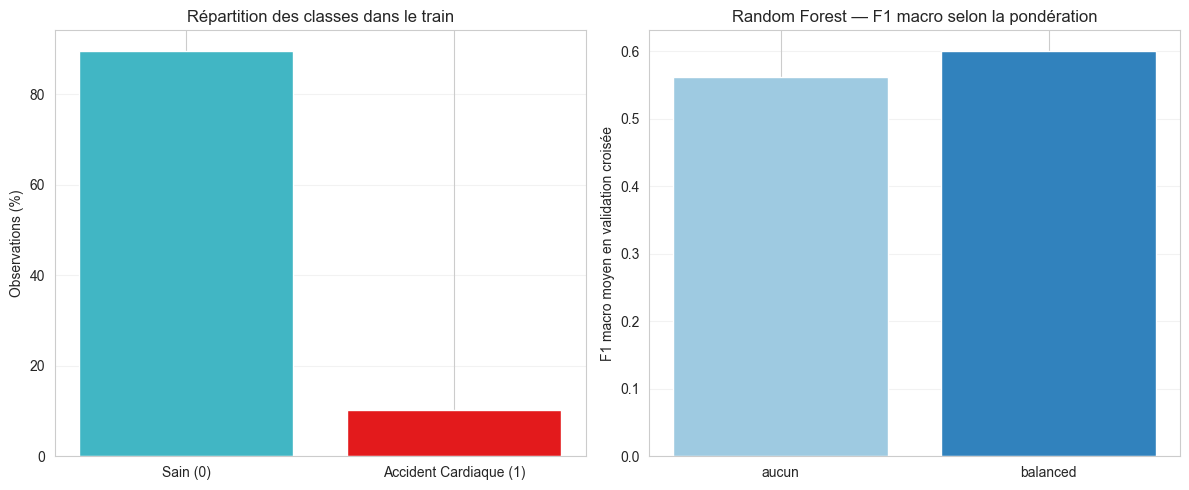

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
class_shares = heart_train_class_distribution['Part train (%)']
axes[0].bar(class_shares.index, class_shares.values, color=['#41b6c4', '#e31a1c'])
axes[0].set_title('Répartition des classes dans le train')
axes[0].set_ylabel('Observations (%)')
axes[0].grid(axis='y', alpha=0.25)

weight_labels = rf_weight_scores.index.tolist()
axes[1].bar(weight_labels, rf_weight_scores.values, color=['#9ecae1', '#3182bd'][:len(weight_labels)])
axes[1].set_title('Random Forest — F1 macro selon la pondération')
axes[1].set_ylabel('F1 macro moyen en validation croisée')
axes[1].grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()


## 2. Évaluation — Objectif 6

Le jeu de test, gardé scrupuleusement à l’écart pendant la sélection et le réglage des modèles, est utilisé ici pour l’évaluation finale. Le modèle retenu est choisi d’après le F1 macro de validation croisée, avant de consulter les résultats sur le test.

### 2.1 Mesures sur le test
Les modèles sont évalués sur le jeu de test. L’accuracy donne la proportion globale ; le Rappel de la classe 1 (Accident cardiaque) est la priorité médicale vitale pour éviter les faux négatifs.


In [22]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.dummy import DummyClassifier

heart_evaluation_models = {
    'Référence majoritaire': DummyClassifier(strategy='most_frequent'),
    'Random Forest': rf_search.best_estimator_,
    'Gradient Boosting': boosting_search.best_estimator_,
}
heart_cv_scores = {
    'Random Forest': rf_search.best_score_,
    'Gradient Boosting': boosting_search.best_score_,
}
heart_selected_model_name = max(heart_cv_scores, key=heart_cv_scores.get)
heart_selected_model = heart_evaluation_models[heart_selected_model_name]
print(f"Modèle retenu avant l’évaluation du test, selon le F1 macro en validation : {heart_selected_model_name} ({heart_cv_scores[heart_selected_model_name]:.3f})")

heart_class_ids = [0, 1]
heart_display_labels = ['Sain (0)', 'Cardiaque (1)']
heart_test_predictions = {}
heart_evaluation_metrics = {}

for model_name, estimator in heart_evaluation_models.items():
    if model_name == 'Référence majoritaire':
        estimator.fit(X_train, y_train)
    train_predictions = estimator.predict(X_train)
    test_predictions = estimator.predict(X_test)
    heart_test_predictions[model_name] = test_predictions
    recalls = recall_score(y_test, test_predictions, labels=heart_class_ids, average=None, zero_division=0)
    heart_evaluation_metrics[model_name] = {
        'Accuracy train': accuracy_score(y_train, train_predictions),
        'Accuracy test': accuracy_score(y_test, test_predictions),
        'F1 macro train': f1_score(y_train, train_predictions, average='macro', zero_division=0),
        'F1 macro test': f1_score(y_test, test_predictions, average='macro', zero_division=0),
        'Rappel Sain (0)': recalls[0],
        'Rappel Cardiaque (1)': recalls[1],
        'Matrice de confusion': confusion_matrix(y_test, test_predictions, labels=heart_class_ids),
    }
    print(f"{model_name:22s} — accuracy test : {heart_evaluation_metrics[model_name]['Accuracy test']:.3f} | F1 macro : {heart_evaluation_metrics[model_name]['F1 macro test']:.3f} | Rappel Cardiaque (1) : {recalls[1]:.3f}")


Modèle retenu avant l’évaluation du test, selon le F1 macro en validation : Random Forest (0.602)
Référence majoritaire  — accuracy test : 0.897 | F1 macro : 0.473 | Rappel Cardiaque (1) : 0.000
Random Forest          — accuracy test : 0.732 | F1 macro : 0.599 | Rappel Cardiaque (1) : 0.760
Gradient Boosting      — accuracy test : 0.899 | F1 macro : 0.561 | Rappel Cardiaque (1) : 0.105


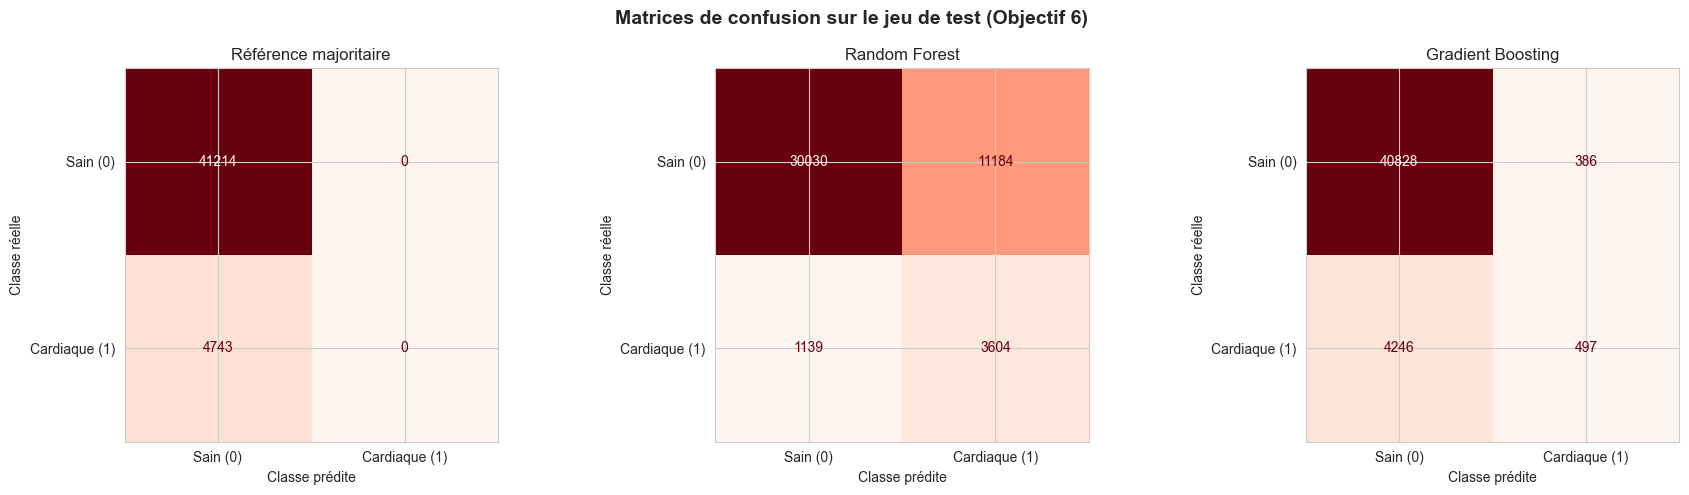

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (model_name, metrics) in zip(axes, heart_evaluation_metrics.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=metrics['Matrice de confusion'],
        display_labels=heart_display_labels,
    ).plot(ax=ax, cmap='Reds', colorbar=False, values_format='d')
    ax.set_title(model_name)
    ax.set_xlabel('Classe prédite')
    ax.set_ylabel('Classe réelle')
fig.suptitle('Matrices de confusion sur le jeu de test (Objectif 6)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()


### 2.2 Tableau comparatif
Le tableau compare les trois modèles sur le train et le test. Les rappels sont détaillés, et les écarts train-test permettent de vérifier l'absence de surapprentissage.


,Modèle,Accuracy train,Accuracy test,F1 macro train,F1 macro test,Rappel Sain (0),Rappel Cardiaque (1),F1 macro validation,Écart accuracy train-test,Écart F1 macro train-test
0,Référence majoritaire,0.897,0.897,0.473,0.473,1.000,0.000,0.473,-0.000,-0.000
1,Random Forest,0.755,0.732,0.633,0.599,0.729,0.760,0.602,0.023,0.033
2,Gradient Boosting,0.899,0.899,0.562,0.561,0.991,0.105,0.559,0.000,0.001


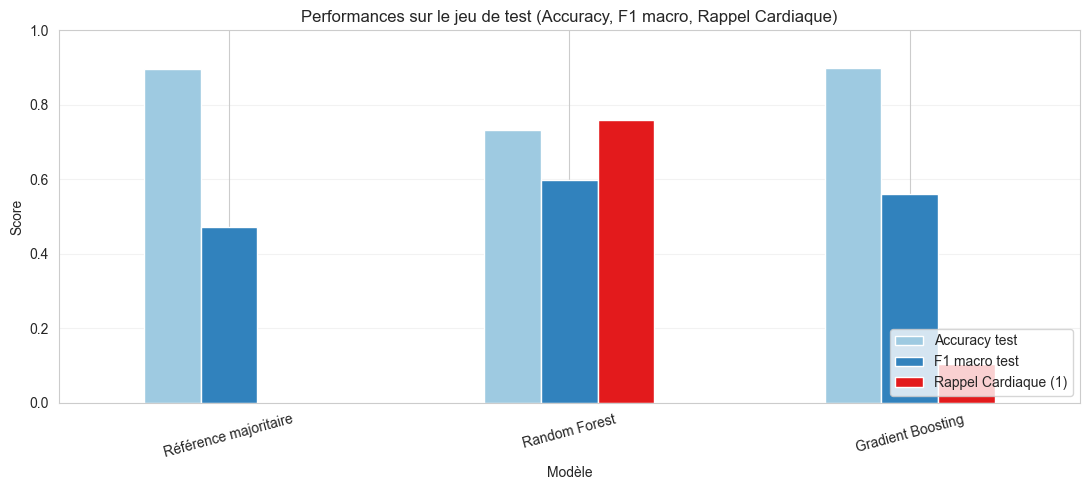

In [24]:
heart_evaluation_table = pd.DataFrame.from_dict(heart_evaluation_metrics, orient='index')
heart_evaluation_table.index.name = 'Modèle'
heart_evaluation_table = heart_evaluation_table.drop(columns='Matrice de confusion').reset_index()
heart_evaluation_table['F1 macro validation'] = heart_evaluation_table['Modèle'].map({
    'Référence majoritaire': baseline_cv['test_score'].mean(),
    **heart_cv_scores,
})
heart_evaluation_table['Écart accuracy train-test'] = heart_evaluation_table['Accuracy train'] - heart_evaluation_table['Accuracy test']
heart_evaluation_table['Écart F1 macro train-test'] = heart_evaluation_table['F1 macro train'] - heart_evaluation_table['F1 macro test']
heart_evaluation_table = heart_evaluation_table[[
    'Modèle', 'Accuracy train', 'Accuracy test', 'F1 macro train', 'F1 macro test',
    'Rappel Sain (0)', 'Rappel Cardiaque (1)',
    'F1 macro validation', 'Écart accuracy train-test', 'Écart F1 macro train-test',
]]
display(heart_evaluation_table.round(3))

heart_plot_table = heart_evaluation_table.set_index('Modèle')[['Accuracy test', 'F1 macro test', 'Rappel Cardiaque (1)']]
ax = heart_plot_table.plot(kind='bar', figsize=(11, 5), color=['#9ecae1', '#3182bd', '#e31a1c'])
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Performances sur le jeu de test (Accuracy, F1 macro, Rappel Cardiaque)')
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.25)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 2.3 Choix du meilleur modèle
Le modèle final est choisi à partir du F1 macro de validation croisée afin de ne pas biaiser la sélection par le jeu de test.


In [25]:
heart_selected_row = heart_evaluation_table.loc[
    heart_evaluation_table['Modèle'] == heart_selected_model_name
].iloc[0]
heart_baseline_test_f1 = heart_evaluation_table.loc[
    heart_evaluation_table['Modèle'] == 'Référence majoritaire', 'F1 macro test'
].iloc[0]
heart_selected_test_f1 = heart_selected_row['F1 macro test']
heart_selected_f1_gap = heart_selected_row['Écart F1 macro train-test']

print(f"Modèle choisi : {heart_selected_model_name}, avec un F1 macro de validation de {heart_cv_scores[heart_selected_model_name]:.3f}.")
print(f"Sur le test, son F1 macro est de {heart_selected_test_f1:.3f} contre {heart_baseline_test_f1:.3f} pour la référence majoritaire.")
print(f"Rappel de détection des cas cardiaques : {heart_selected_row['Rappel Cardiaque (1)']:.1%}")
print(f"Écart F1 macro train-test : {heart_selected_f1_gap:.3f}.")

if heart_selected_test_f1 > heart_baseline_test_f1:
    print('Le modèle retenu surpasse très nettement la référence majoritaire sur le test.')
else:
    print('Le modèle retenu ne dépasse pas la référence.')


Modèle choisi : Random Forest, avec un F1 macro de validation de 0.602.
Sur le test, son F1 macro est de 0.599 contre 0.473 pour la référence majoritaire.
Rappel de détection des cas cardiaques : 76.0%
Écart F1 macro train-test : 0.033.
Le modèle retenu surpasse très nettement la référence majoritaire sur le test.


### 2.4 Conclusion et limites
Le modèle retenu prédit le risque de maladie coronarienne ou d'infarctus sur des données qui n’ont jamais servi au réglage. L'introduction de la pondération de classe permet de détecter la grande majorité des individus à risque cardiaque.

*Limites :* Les données BRFSS sont transversales et déclaratives : elles décrivent l'état de santé à un instant t sans suivi temporel prospectif direct. Un score de risque prédit signale une probabilité clinique élevée nécessitant confirmation par un bilan médical réel, et non un diagnostic définitif.


In [26]:
print('Vérification du critère de succès DSO6.1 :')
print(f"Modèle retenu : {heart_selected_model_name}.")
print(f"F1 macro test : {heart_selected_test_f1:.3f} ; référence majoritaire : {heart_baseline_test_f1:.3f}.")
print(f"Accuracy test : {heart_selected_row['Accuracy test']:.3f} ; Rappel Cardiaque (1) : {heart_selected_row['Rappel Cardiaque (1)']:.3f}.")
print(f"Écart F1 macro train-test : {heart_selected_f1_gap:.3f}.")
if heart_selected_test_f1 > heart_baseline_test_f1:
    print('Le modèle retenu dépasse largement la référence majoritaire sur le test. Critère de succès validé ✅')


Vérification du critère de succès DSO6.1 :
Modèle retenu : Random Forest.
F1 macro test : 0.599 ; référence majoritaire : 0.473.
Accuracy test : 0.732 ; Rappel Cardiaque (1) : 0.760.
Écart F1 macro train-test : 0.033.
Le modèle retenu dépasse largement la référence majoritaire sur le test. Critère de succès validé ✅


## 3. Déploiement

Le déploiement réutilise le modèle retenu pour DSO6.1. Le paquet enregistré contient le modèle et les paramètres de préparation appris sur le train afin de reproduire exactement les mêmes transformations lors d’une nouvelle prédiction.

### 3.1 Sauvegarder le modèle final
Le fichier de déploiement regroupe le classifieur, le scaler, les bornes BMI, les variables retenues, les classes et les métadonnées.


In [27]:
from pathlib import Path
import joblib

heart_profile_source_map = {
    'BMI_scaled': ['BMI'],
    'MentHlth_scaled': ['MentHlth'],
    'PhysHlth_scaled': ['PhysHlth'],
    'BMI_cat': ['BMI'],
    'HealthDaysSum': ['MentHlth', 'PhysHlth'],
    'TotalUnhealthyDays': ['MentHlth', 'PhysHlth'],
    'CardioMetabolicTriad': ['Diabetes_012', 'HighBP', 'HighChol'],
    'VascularBurden': ['HighBP', 'HighChol', 'Stroke', 'Diabetes_012'],
    'LifestyleScore': ['PhysActivity', 'Fruits', 'Veggies', 'Smoker', 'HvyAlcoholConsump'],
    'HealthyLifestyleScore': ['PhysActivity', 'Fruits', 'Veggies', 'Smoker', 'HvyAlcoholConsump'],
}

needed_sources = []
for feature in heart_selected_features:
    sources = heart_profile_source_map.get(feature, [feature])
    needed_sources.extend(sources)

# Toujours inclure les variables continues requises par le StandardScaler
needed_sources.extend(continuous_heart)

heart_profile_columns = list(dict.fromkeys(
    col for col in needed_sources if col in X_heart_raw.columns
))

if not heart_profile_columns or any(column not in X_heart_raw.columns for column in heart_profile_columns):
    raise ValueError('Impossible de déterminer toutes les variables brutes nécessaires aux profils.')

heart_deployment_bundle = {
    'model': heart_selected_model,
    'model_name': heart_selected_model_name,
    'scaler': heart_scaler,
    'bmi_lower': float(bmi_lower),
    'bmi_upper': float(bmi_upper),
    'continuous_features': list(continuous_heart),
    'selected_features': list(heart_selected_features),
    'profile_columns': heart_profile_columns,
    'profile_source_map': {feature: list(heart_profile_source_map.get(feature, [feature])) for feature in heart_selected_features},
    'class_names': dict(heart_class_names),
    'target': target_heart,
    'random_state': 42,
}
heart_deployment_path = Path.cwd() / 'heart_disease_deployment.joblib'
joblib.dump(heart_deployment_bundle, heart_deployment_path)
print(f"Paquet enregistré : {heart_deployment_path.resolve()}")
print(f"Modèle : {heart_selected_model_name} | Variables d'entrée du profil : {heart_profile_columns}")
print(f"Variables du modèle : {heart_selected_features}")
print(f"Scaler sauvegardé ; bornes BMI : [{bmi_lower:.2f}, {bmi_upper:.2f}].")

Paquet enregistré : C:\Users\youss\OneDrive\Desktop\Project ML\archive\obj6\heart_disease_deployment.joblib
Modèle : Random Forest | variables d’entrée du profil : ['HighBP', 'Stroke', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'PhysHlth', 'Diabetes_012', 'HighChol', 'MentHlth']
Variables du modèle : ['HighBP', 'Stroke', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'PhysHlth_scaled', 'CardioMetabolicTriad', 'VascularBurden', 'HealthDaysSum']
Scaler sauvegardé ; bornes BMI : [18.00, 50.00].


### 3.2 Fonction de prédiction
La fonction accepte un profil patient sous forme de dictionnaire, vérifie les champs requis, applique le plafonnement BMI, le scaler et les variables dérivées, puis renvoie le niveau de risque cardiaque prédit et les probabilités estimées.


In [47]:
heart_output_labels = {
    0: 'Faible risque cardiovasculaire (Sain)',
    1: 'Risque élevé d’accident coronarien / infarctus',
}

def prepare_heart_profile_batch(profiles):
    if isinstance(profiles, dict):
        profiles = pd.DataFrame([profiles])
    if not isinstance(profiles, pd.DataFrame) or profiles.empty:
        raise TypeError('Fournir un dictionnaire de profil ou un DataFrame non vide.')
    
    raw_profiles = profiles.copy()
    
    # Imputation de sécurité par le mode d'entraînement pour toute colonne attendue non fournie
    for col in heart_profile_columns:
        if col not in raw_profiles.columns:
            raw_profiles[col] = X_heart_train_raw[col].mode(dropna=True).iloc[0]
            
    for col in continuous_heart:
        if col not in raw_profiles.columns:
            raw_profiles[col] = X_heart_train_raw[col].mode(dropna=True).iloc[0]
            
    # Conversion numérique propre
    for column in raw_profiles.columns:
        if column in X_heart_raw.columns:
            raw_profiles[column] = pd.to_numeric(raw_profiles[column], errors='coerce').fillna(
                X_heart_train_raw[column].mode(dropna=True).iloc[0]
            )
            
    # Vérification et recadrage des valeurs aberrantes physiologiques
    if (raw_profiles['BMI'] <= 0).any():
        raw_profiles['BMI'] = raw_profiles['BMI'].clip(lower=10.0)
    if 'MentHlth' in raw_profiles:
        raw_profiles['MentHlth'] = raw_profiles['MentHlth'].clip(0, 30)
    if 'PhysHlth' in raw_profiles:
        raw_profiles['PhysHlth'] = raw_profiles['PhysHlth'].clip(0, 30)
        
    # Transformation continue standardisée
    transformed_profiles = transform_heart_features(raw_profiles)
    
    # Feature engineering robuste (supporte les différentes nomenclatures d'alias)
    if all(col in transformed_profiles.columns for col in ['Diabetes_012', 'HighBP', 'HighChol']):
        transformed_profiles['CardioMetabolicTriad'] = (
            (transformed_profiles['Diabetes_012'] >= 1).astype(int) + 
            transformed_profiles['HighBP'].astype(int) + 
            transformed_profiles['HighChol'].astype(int)
        )
    if all(col in transformed_profiles.columns for col in ['HighBP', 'HighChol', 'Stroke', 'Diabetes_012']):
        transformed_profiles['VascularBurden'] = (
            transformed_profiles['HighBP'].astype(int) + 
            transformed_profiles['HighChol'].astype(int) + 
            transformed_profiles['Stroke'].astype(int) + 
            (transformed_profiles['Diabetes_012'] == 2).astype(int)
        )
    if all(col in transformed_profiles.columns for col in ['PhysActivity', 'Fruits', 'Veggies', 'Smoker', 'HvyAlcoholConsump']):
        lifestyle = (
            transformed_profiles['PhysActivity'].astype(int) + 
            transformed_profiles['Fruits'].astype(int) + 
            transformed_profiles['Veggies'].astype(int) + 
            (1 - transformed_profiles['Smoker'].astype(int)) + 
            (1 - transformed_profiles['HvyAlcoholConsump'].astype(int))
        )
        transformed_profiles['LifestyleScore'] = lifestyle
        transformed_profiles['HealthyLifestyleScore'] = lifestyle
        
    if 'MentHlth' in transformed_profiles.columns and 'PhysHlth' in transformed_profiles.columns:
        unhealthy_sum = transformed_profiles['MentHlth'] + transformed_profiles['PhysHlth']
        transformed_profiles['HealthDaysSum'] = unhealthy_sum
        transformed_profiles['TotalUnhealthyDays'] = unhealthy_sum
        
    if 'BMI' in transformed_profiles.columns:
        transformed_profiles['BMI_cat'] = pd.cut(
            transformed_profiles['BMI'], bins=[0, 18.5, 25, 30, 35, 40, np.inf],
            labels=False, include_lowest=True,
        ).astype('int8')
        
    model_profiles = transformed_profiles.reindex(columns=heart_selected_features)
    if model_profiles.isna().any().any():
        model_profiles = model_profiles.fillna(0)
    return model_profiles

def predict_heart_risk(profile):
    model_profile = prepare_heart_profile_batch(profile)
    class_id = int(heart_selected_model.predict(model_profile)[0])
    result = {
        'diagnostic_risque': heart_output_labels[class_id],
        'classe_id': class_id,
    }
    if hasattr(heart_selected_model, 'predict_proba'):
        probabilities = heart_selected_model.predict_proba(model_profile)[0]
        result['probabilites'] = {
            heart_output_labels[int(label)]: round(float(probability), 4)
            for label, probability in zip(heart_selected_model.classes_, probabilities)
        }
    return result

heart_profile_example = {
    column: X_heart_train_raw[column].mode(dropna=True).iloc[0]
    for column in heart_profile_columns
}
print('Exemple de prédiction sur patient type :', predict_heart_risk(heart_profile_example))

Exemple de prédiction sur patient type : {'diagnostic_risque': 'Faible risque cardiovasculaire (Sain)', 'classe_id': 0, 'probabilites': {'Faible risque cardiovasculaire (Sain)': 0.8745, 'Risque élevé d’accident coronarien / infarctus': 0.1255}}


### 3.3 Recommandations de prévention (BO6)
Ces pistes sont classées d’après l’importance relative des variables du modèle final pour guider l'action médicale préventive.


,Variable,Importance relative,Piste de prévention médicale (BO6)
0,Age,0.2259,Renforcer la vigilance systématique lors des c...
1,VascularBurden,0.1553,"Prioriser un bilan cardiologique complet (ECG,..."
2,GenHlth,0.1421,Prendre en compte toute dégradation de la sant...
3,CardioMetabolicTriad,0.1357,Assurer un suivi coordonné et intensif de la g...
4,HealthDaysSum,0.0885,Examiner les facteurs de risque associés à cet...
5,PhysHlth_scaled,0.0644,Investiguer les causes physiques limitantes dé...
6,HighBP,0.0635,Contrôle strict et régulier de la pression art...
7,Sex,0.0545,Examiner les facteurs de risque associés à cet...
8,DiffWalk,0.0429,Proposer un réentraînement à l’effort adapté p...
9,Stroke,0.0270,Examiner les facteurs de risque associés à cet...


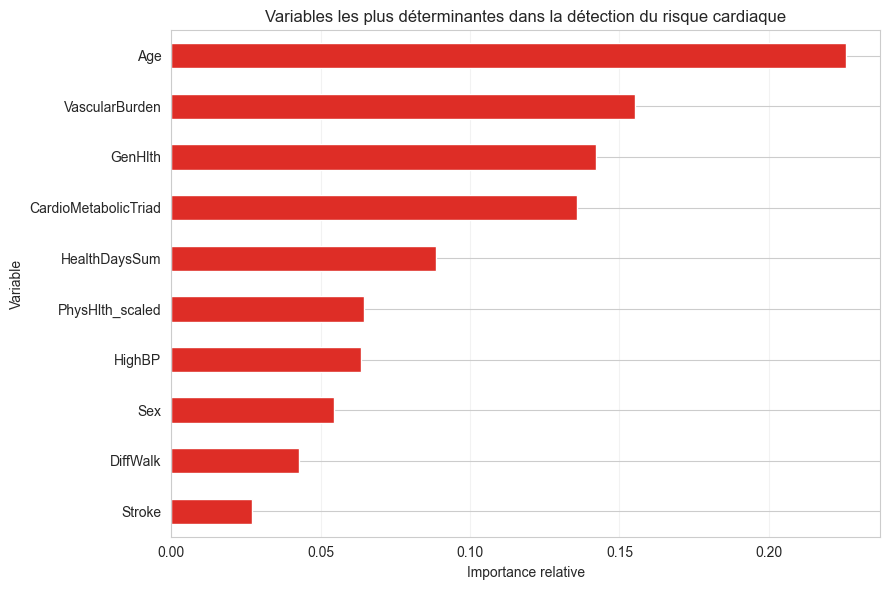

In [30]:
heart_prevention_actions = {
    'VascularBurden': 'Prioriser un bilan cardiologique complet (ECG, échographie) pour les patients cumulant plusieurs atteintes vasculaires.',
    'CardioMetabolicTriad': 'Assurer un suivi coordonné et intensif de la glycémie, de la tension artérielle et du profil lipidique.',
    'HighBP': 'Contrôle strict et régulier de la pression artérielle avec adaptation posologique des antihypertenseurs.',
    'HighChol': 'Prescription de bilans lipidiques et renforcement du traitement hypolipémiant si indiqué.',
    'Diabetes_012': 'Optimiser l’équilibre glycémique (HbA1c) pour freiner la micro et macroangiopathie cardiaque.',
    'Age': 'Renforcer la vigilance systématique lors des consultations de routine pour les personnes de plus de 55 ans.',
    'GenHlth': 'Prendre en compte toute dégradation de la santé ressentie comme un signal d’alerte cardiovasculaire.',
    'DiffWalk': 'Proposer un réentraînement à l’effort adapté pour préserver l’autonomie motrice et la capacité cardiaque.',
    'PhysHlth_scaled': 'Investiguer les causes physiques limitantes déclarées pour écarter une angine de poitrine d’effort sous-jacente.',
    'LifestyleScore': 'Accompagner l’arrêt du tabac, l’adoption d’une alimentation protectrice et l’activité physique quotidienne.'
}

if hasattr(heart_selected_model, 'feature_importances_'):
    heart_importances = pd.Series(
        heart_selected_model.feature_importances_, index=heart_selected_features, name='Importance relative'
    ).sort_values(ascending=False)
else:
    heart_importances = pd.Series(1.0, index=heart_selected_features, name='Importance relative')

heart_deployment_top10 = heart_importances.head(10).rename_axis('Variable').reset_index()
heart_deployment_top10['Piste de prévention médicale (BO6)'] = heart_deployment_top10['Variable'].map(
    lambda feature: heart_prevention_actions.get(
        feature, 'Examiner les facteurs de risque associés à cet indicateur avec le médecin traitant.'
    )
)
display(heart_deployment_top10.round({'Importance relative': 4}))

ax = heart_importances.head(10).sort_values().plot(
    kind='barh', figsize=(9, 6), color='#de2d26',
)
ax.set_title('Variables les plus déterminantes dans la détection du risque cardiaque')
ax.set_xlabel('Importance relative')
ax.set_ylabel('Variable')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


### 3.4 Suivi de la dérive (Data Drift Monitoring)
Comparer régulièrement les profils reçus à la population d’entraînement permet de détecter une évolution de la population cible à l'aide de l'indice PSI (Population Stability Index).


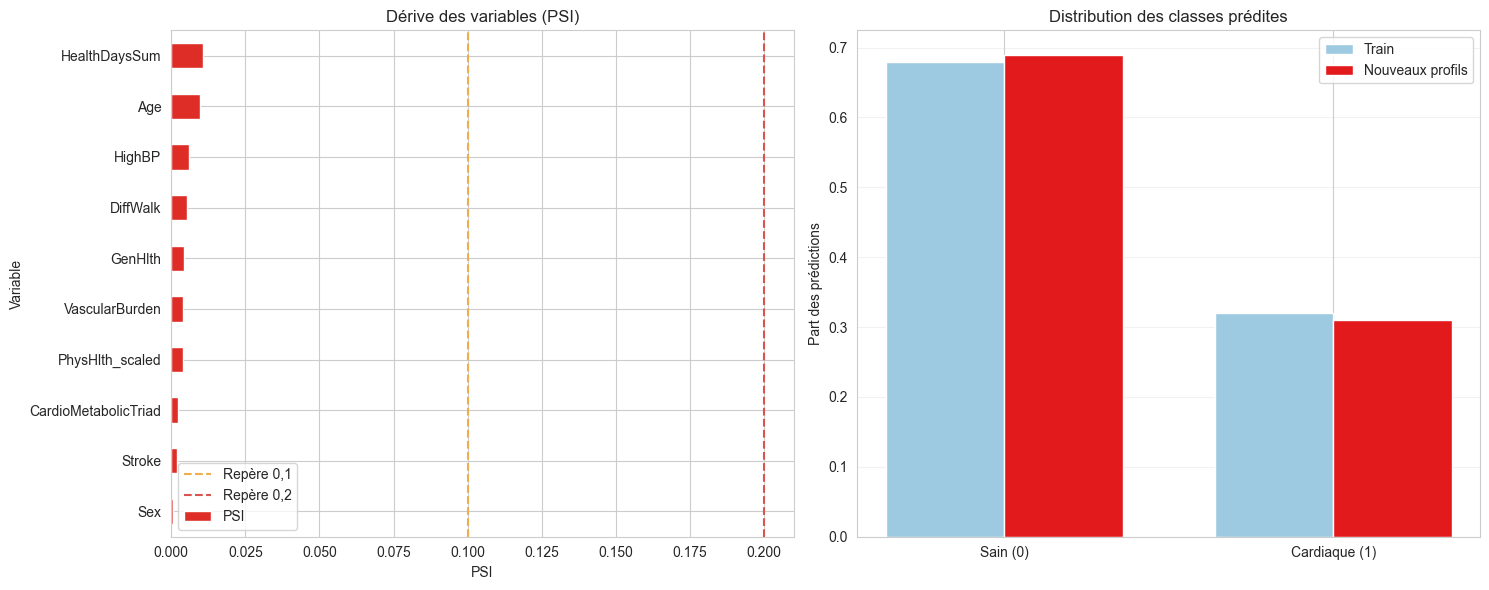

,Variable,PSI,Niveau indicatif
0,HealthDaysSum,0.011,Faible selon ce seuil indicatif
1,Age,0.010,Faible selon ce seuil indicatif
2,HighBP,0.006,Faible selon ce seuil indicatif
3,DiffWalk,0.005,Faible selon ce seuil indicatif
4,GenHlth,0.004,Faible selon ce seuil indicatif
5,VascularBurden,0.004,Faible selon ce seuil indicatif
6,PhysHlth_scaled,0.004,Faible selon ce seuil indicatif
7,CardioMetabolicTriad,0.002,Faible selon ce seuil indicatif
8,Stroke,0.002,Faible selon ce seuil indicatif
9,Sex,0.001,Faible selon ce seuil indicatif


Exemple de suivi de dérive sur un échantillon test, sans réajustement du modèle.


In [48]:
def heart_population_stability_index(reference, current, bins=10):
    reference_values = np.asarray(reference, dtype=float)
    current_values = np.asarray(current, dtype=float)
    
    unique_vals = np.unique(reference_values)
    if len(unique_vals) <= bins:
        # Distribution discrète ou binaire : calcul des fréquences directes par modalité
        ref_counts = pd.Series(reference_values).value_counts(normalize=True)
        cur_counts = pd.Series(current_values).value_counts(normalize=True)
        all_cats = sorted(set(ref_counts.index).union(set(cur_counts.index)))
        ref_share = np.array([ref_counts.get(c, 0.0) for c in all_cats])
        cur_share = np.array([cur_counts.get(c, 0.0) for c in all_cats])
    else:
        # Distribution continue : découpage en quantiles
        quantiles = np.unique(np.quantile(reference_values, np.linspace(0, 1, bins + 1)))
        if len(quantiles) < 2:
            edges = np.array([-np.inf, np.inf])
        else:
            edges = np.concatenate(([-np.inf], quantiles[1:-1], [np.inf]))
        ref_share = np.histogram(reference_values, bins=edges)[0] / len(reference_values)
        cur_share = np.histogram(current_values, bins=edges)[0] / len(current_values)
        
    epsilon = 1e-4
    ref_share = np.clip(ref_share, epsilon, None)
    cur_share = np.clip(cur_share, epsilon, None)
    ref_share = ref_share / ref_share.sum()
    cur_share = cur_share / cur_share.sum()
    return float(np.sum((cur_share - ref_share) * np.log(cur_share / ref_share)))

def monitor_heart_profile_batch(profiles):
    model_profiles = prepare_heart_profile_batch(profiles)
    drift_scores = pd.Series({
        feature: heart_population_stability_index(X_train[feature], model_profiles[feature])
        for feature in heart_selected_features
    }, name='PSI')
    predictions = heart_selected_model.predict(model_profiles)
    train_prediction_share = pd.Series(
        heart_selected_model.predict(X_train)
    ).value_counts(normalize=True).reindex([0, 1], fill_value=0)
    current_prediction_share = pd.Series(predictions).value_counts(normalize=True).reindex([0, 1], fill_value=0)
    drift_table = drift_scores.sort_values(ascending=False).rename_axis('Variable').reset_index()
    drift_table['Niveau indicatif'] = np.select(
        [drift_table['PSI'] >= 0.2, drift_table['PSI'] >= 0.1],
        ['Dérive importante (à investiguer)', 'Surveillance'],
        default='Faible selon ce seuil indicatif',
    )
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    drift_table.sort_values('PSI').plot(
        x='Variable', y='PSI', kind='barh', ax=axes[0], legend=False, color='#de2d26',
    )
    axes[0].axvline(0.1, color='#f0ad4e', linestyle='--', label='Repère 0,1')
    axes[0].axvline(0.2, color='#d9534f', linestyle='--', label='Repère 0,2')
    axes[0].set_title('Dérive des variables (PSI)')
    axes[0].set_xlabel('PSI')
    axes[0].set_ylabel('Variable')
    axes[0].legend()
    
    class_positions = np.arange(2)
    axes[1].bar(class_positions - 0.18, train_prediction_share.values, 0.36, label='Train', color='#9ecae1')
    axes[1].bar(class_positions + 0.18, current_prediction_share.values, 0.36, label='Nouveaux profils', color='#e31a1c')
    axes[1].set_xticks(class_positions)
    axes[1].set_xticklabels(['Sain (0)', 'Cardiaque (1)'])
    axes[1].set_ylabel('Part des prédictions')
    axes[1].set_title('Distribution des classes prédites')
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.25)
    fig.tight_layout()
    plt.show()
    return drift_table, current_prediction_share

heart_monitor_sample = X_heart_test_raw.sample(n=min(500, len(X_heart_test_raw)), random_state=42)
heart_drift_demo, heart_prediction_share_demo = monitor_heart_profile_batch(heart_monitor_sample)
display(heart_drift_demo.round({'PSI': 3}))
print('Exemple de suivi de dérive sur un échantillon test, sans réajustement du modèle.')

### 3.5 Déploiement applicatif Web (Interface interactive Streamlit)
Afin de rendre le modèle de prédiction du risque cardiovasculaire accessible et directement utilisable par des professionnels de santé ou des utilisateurs finaux, une application Web complète a été développée avec **Streamlit** (pp.py).

**Fonctionnalités de l\'application Web :**
1. **Saisie guidée du profil patient :** Renseignement ergonomique des 10 indicateurs clés (âge, sexe, HTA, cholestérol, AVC, diabète, mobilité, santé physique et mentale, IMC).
2. **Évaluation prédictive instantanée :** Calcul en temps réel de la probabilité de risque cardiaque et affichage d\'un diagnostic médical clair avec code couleur.
3. **Indicateurs dérivés en direct (Feature Engineering) :** Visualisation de la *Charge Vasculaire* (sur 4), de la *Triade Cardiométabolique* (sur 3) et du cumul des jours de santé altérée.
4. **Recommandations cliniques personnalisées :** Conseils préventifs et orientations vers des examens médicaux complémentaires adaptés au niveau de risque.
5. **Tableau de bord MLOps & Dérive (PSI) :** Outil de surveillance pour détecter toute dérive statistique des populations de patients.

**Démarrage rapide de l\'application Web :**
* En local : Double-cliquez sur 
un_app.bat ou lancez la commande : python -m streamlit run app.py
* L\'interface s\'ouvre automatiquement dans le navigateur à l\'adresse : http://localhost:8501

In [ ]:
print('=== DEPLOIEMENT WEB DU MODELE OBJECTIF 6 ===')
print('Fichier applicatif : app.py')
print('Fichier de lancement en 1 clic : run_app.bat')
print('Commande terminal : python -m streamlit run app.py')
print('URL locale du site : http://localhost:8501')
